Classification -> o/p -> Categories.

If 2 Categories -> Binary Classification.

Suppose 1000 DataPoints -> 900 yes and 100 No, Ratio is 9:1  Such situation is imbalanced dataset.

What happens in ML model creating, when you train, which will be responsible in predicting, it get baised towards the max no. of data points because of imbalanced data points. 

So its necessary to fix this imbalanced dataset, and we will try to make this both the data points equal. We can do this by using Two Techniques: 1. UpSampling 2. DownSampling.

In Upsampling we can increase the data points from 100 which in minority,
In Downsampling Try to reduce the data points from 900 which in majority.




In [20]:
pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 507.9 kB/s eta 0:00:16
   -- ------------------------------------- 0.5/8.4 MB 507.9 kB/s eta 0:00:16
   -- ------------------------------------- 0.5/8.4 MB 507.9 kB/s eta 0:00:16
   --- ------------------------------------ 0.8/8.4 MB 519.3 kB/s eta 0:00:15
   --- ------------------------------------ 0.8/8.4 MB 519.3 kB/s eta 0:00:15
   ----- ---------------------------------- 1.0/8.4 MB 541.6 kB/s eta 0:00:14
   ----- ---------------------------------- 1.0/8


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd

# Set the random seed for reproducibility
np.random.seed(123)

# Create a dataframe with two classes
n_samples = 1000
class_0_ratio = 0.9
n_class_0 = int(n_samples * class_0_ratio)
n_class_1 = n_samples - n_class_0

In [9]:
n_class_0,n_class_1

(900, 100)

In [8]:
# The seed makes the random results reproducible.

loc   → where the distribution is centered

scale → how spread out the values are

size  → how many values to generate

In [10]:
## Create my DataFrame with Imbalanced Dataset.
class_0 = pd.DataFrame({
    'feature_1' : np.random.normal(loc=0, scale=1, size=n_class_0),
    'feature_2' : np.random.normal(loc=0, scale=1, size=n_class_0),
    'target': [0] * n_class_0
})

class_1 = pd.DataFrame({
    'feature_1' : np.random.normal(loc=2, scale=1, size=n_class_1),
    'feature_2' : np.random.normal(loc=2, scale=1, size=n_class_1),
    'target': [1] * n_class_1
})

In [11]:
class_0.head()

,feature_1,feature_2,target
0,-1.774224,0.285744,0
1,-1.201377,0.333279,0
2,1.096257,0.531807,0
3,0.861037,-0.354766,0
4,-1.520367,-1.120815,0


In [12]:
class_1.head()

,feature_1,feature_2,target
0,-0.643425,2.571923,1
1,1.551009,1.782767,1
2,1.641093,2.054318,1
3,2.133194,2.155998,1
4,1.355758,2.467810,1


In [13]:
df=pd.concat([class_0, class_1]).reset_index(drop=True)

In [15]:
df.head()

,feature_1,feature_2,target
0,-1.774224,0.285744,0
1,-1.201377,0.333279,0
2,1.096257,0.531807,0
3,0.861037,-0.354766,0
4,-1.520367,-1.120815,0


In [16]:
df['target'].value_counts()

target
0    900
1    100
Name: count, dtype: int64

In [17]:
## upsampling
df_minority=df[df['target']==1]
df_majority=df[df['target']==0]

In [21]:
from sklearn.utils import resample
df_minority_upsampled = resample(df_minority, replace=True, #Sample with replacement (means: A row that has already been selected can be selected again.)
         n_samples=len(df_majority), 
         random_state=42
         )

In [22]:
df_minority_upsampled.shape

(900, 3)

In [23]:
df_minority_upsampled.head()

,feature_1,feature_2,target
951,2.905343,1.495151,1
992,2.000977,1.814833,1
914,1.927957,2.280911,1
971,2.819483,2.964646,1
960,2.456515,1.833528,1


In [24]:
df_upsampled = pd.concat([df_majority,df_minority_upsampled])

In [25]:
df_upsampled['target'].value_counts()

target
0    900
1    900
Name: count, dtype: int64

Down Sampling


In [26]:
## Create my DataFrame with Imbalanced Dataset.
class_0 = pd.DataFrame({
    'feature_1' : np.random.normal(loc=0, scale=1, size=n_class_0),
    'feature_2' : np.random.normal(loc=0, scale=1, size=n_class_0),
    'target': [0] * n_class_0
})

class_1 = pd.DataFrame({
    'feature_1' : np.random.normal(loc=2, scale=1, size=n_class_1),
    'feature_2' : np.random.normal(loc=2, scale=1, size=n_class_1),
    'target': [1] * n_class_1
})

df = pd.concat([class_0, class_1]).reset_index(drop=True)

# Check the class distribution
print(df['target'].value_counts())

target
0    900
1    100
Name: count, dtype: int64


In [27]:
## downsampling
df_minority=df[df['target']==1]
df_majority=df[df['target']==0]

In [29]:
df_majority_downsampled = resample(df_majority, replace=False, #Sample with replacement
         n_samples=len(df_minority), 
         random_state=42
         )

In [30]:
df_majority_downsampled.shape

(100, 3)

In [31]:
df_downsampled = pd.concat([df_minority, df_majority_downsampled])

In [32]:
df_downsampled.target.value_counts()

target
1    100
0    100
Name: count, dtype: int64

**SMOTE**

SMOTE balances an imbalanced dataset by creating synthetic examples of the minority class rather than simply duplicating existing examples. Using Interploating technique

In [1]:
from sklearn.datasets import make_classification

In [2]:
X,y=make_classification(n_samples=1000,n_redundant=0,n_features=2,n_clusters_per_class=1,
                        weights=[0.90],random_state=12)
#X is my independent feature, y is my dependent features(target/output).
#I have 1000 samples, 2 features, 90% of the data belongs to one class and 10% belongs
# to another class

redundant=0 means we don't want make_classifaication()to generate any additional features that are derived from other features

In [3]:
import pandas as pd
df1= pd.DataFrame(X,columns=['f1','f2'])
df2= pd.DataFrame(y,columns=['Target'])
final_df=pd.concat([df1,df2],axis=1)
final_df.head()

,f1,f2,Target
0,-0.762898,-0.706808,0
1,-1.075436,-1.051162,0
2,-0.610115,-0.909802,0
3,-2.023284,-0.428945,1
4,-0.812921,-1.316206,0


In [5]:
final_df['Target'].value_counts()

Target
0    900
1    100
Name: count, dtype: int64

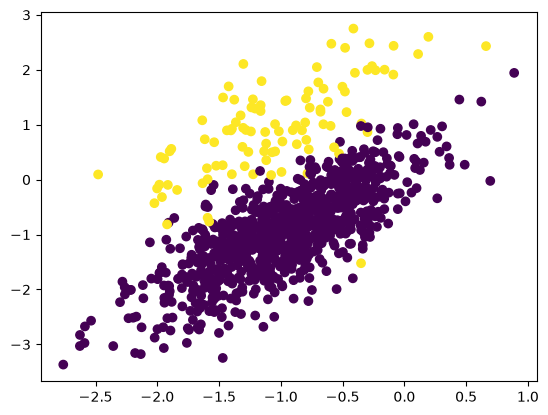

In [6]:
import matplotlib.pyplot as plt
plt.scatter(final_df['f1'],final_df['f2'],c=final_df['Target'])

In [7]:
pip install imblearn


   ---------------------------------------- 0/3 [sklearn-compat]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ---------------------------------------- 3/3 [imblearn]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
from imblearn.over_sampling import SMOTE

In [9]:
#transform the dataset
oversample= SMOTE()
X,y=oversample.fit_resample(final_df[['f1','f2']],final_df['Target'])

In [10]:
X.shape

(1800, 2)

In [11]:
len(y[y==0])

900

In [12]:
len(y[y==1])

900

In [13]:
df1=pd.DataFrame(X, columns=['f1','f2'])
df2=pd.DataFrame(y, columns=['Target'])
oversampled_df=pd.concat([df1,df2],axis=1)

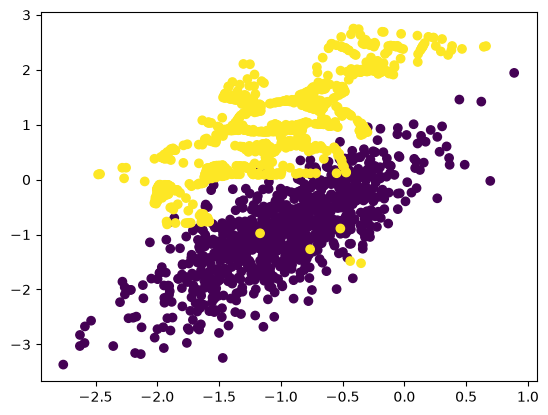

In [14]:
plt.scatter(oversampled_df['f1'],oversampled_df['f2'],c=oversampled_df['Target'])

**5 number Summary and Box Plot**

In [15]:
##minimum ,maximum,Q1,Q2,Q3

In [16]:
import numpy as np

In [20]:
lst_marker=[45,32,56,75,89,54,32,89,90,87,67,54,45,98,99,67,74]
minimum,Q1,median,Q3,maximum=np.quantile(lst_marker,[0,0.25,0.50,0.75,1])

In [21]:
#IQR(Interquartile Range)
IQR=Q3-Q1
print(IQR)

35.0


In [22]:
lower_fence=Q1-1.5*(IQR)
higher_fence=Q1-1.5*(IQR)